## 1. 원본 로딩 및 구로구 추출

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATASET_KEY = "소상공인시장진흥공단_상가(상권)정보_서울_202609"

def find_repo():
    cwd = Path.cwd().resolve()
    for path in [cwd, *cwd.parents]:
        if path.name == "do_not_lung" and (path / "notebooks").is_dir():
            return path
        candidate = path / "do_not_lung"
        if (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("do_not_lung 저장소를 찾지 못했습니다.")

REPO = find_repo()
DATA_ROOT = REPO.parent / "data"
RAW_ROOT = DATA_ROOT / "raw_data"
OUT_DIR = DATA_ROOT / "processed_data" / DATASET_KEY

candidates = sorted(
    RAW_ROOT.rglob(DATASET_KEY + "*.csv"),
    key=lambda p: (p.name != DATASET_KEY + ".csv", str(p))
)
if not candidates:
    raise FileNotFoundError(f"원본 CSV가 없습니다: {RAW_ROOT}")

RAW_PATH = candidates[0]

for encoding in ["utf-8-sig", "cp949"]:
    try:
        header = pd.read_csv(
            RAW_PATH, encoding=encoding, nrows=0
        ).columns.tolist()
        break
    except UnicodeDecodeError:
        continue
else:
    raise UnicodeError("원본 CSV 인코딩 확인 실패")

required = [
    "상가업소번호", "상호명", "시도명", "시군구명",
    "상권업종대분류명", "행정동명", "경도", "위도"
]
missing_columns = set(required) - set(header)
if missing_columns:
    raise ValueError(f"필수 컬럼 누락: {missing_columns}")

parts = []
source_rows = 0

reader = pd.read_csv(
    RAW_PATH,
    encoding=encoding,
    dtype=str,
    keep_default_na=False,
    chunksize=50000
)

for chunk in reader:
    chunk.insert(
        0, "source_row_id",
        np.arange(source_rows + 1, source_rows + len(chunk) + 1)
    )
    source_rows += len(chunk)

    city = chunk["시도명"].str.strip()
    district = chunk["시군구명"].str.strip()

    mask = (
        city.eq("서울특별시")
        & district.eq("구로구")
    )
    subset = chunk.loc[mask].copy()
    if not subset.empty:
        parts.append(subset)

if not parts:
    raise ValueError("구로구 상가 데이터가 존재하지 않습니다.")

selected = pd.concat(parts, ignore_index=True)
original_columns = header.copy()

print("원본:", RAW_PATH.name)
print("원본 행 수:", source_rows)
print("원본 컬럼 수:", len(header))
print("구로구 행 수:", len(selected))
print("구로구 메모리(MB):", round(
    selected.memory_usage(deep=True).sum() / 1024**2, 2
))
print("pandas:", pd.__version__)
print(selected.head().to_string(index=False))
print(selected.dtypes.to_string())

원본: 소상공인시장진흥공단_상가(상권)정보_서울_202609.csv
원본 행 수: 552422
원본 컬럼 수: 39
구로구 행 수: 18338
구로구 메모리(MB): 44.31
pandas: 3.0.6
 source_row_id               상가업소번호         상호명 지점명 상권업종대분류코드 상권업종대분류명 상권업종중분류코드    상권업종중분류명 상권업종소분류코드   상권업종소분류명 표준산업분류코드          표준산업분류명 시도코드   시도명 시군구코드 시군구명    행정동코드 행정동명      법정동코드 법정동명                지번코드 대지구분코드 대지구분명 지번본번지 지번부번지                  지번주소        도로명코드                도로명 건물본번지 건물부번지                    건물관리번호       건물명                  도로명주소  구우편번호 신우편번호 동정보 층정보 호정보               경도               위도
             2 MA010120220808426074          민촌            I2       음식      I201          한식    I20101     백반/한정식   I56111       한식 일반 음식점업   11 서울특별시 11530  구로구 11530540 구로3동 1153010200  구로동 1153010200111290075      1    대지  1129    75 서울특별시 구로구 구로동 1129-75 115304148336 서울특별시 구로구 디지털로32가길    48       1153010200111290075022534            서울특별시 구로구 디지털로32가길 48 152880 08393       1     126.897837465708 37.4814750546692
            26 MA010120220800747239 솔하임공인중개사사

## 2. 전처리 및 데이터 품질 검증

In [2]:
clean = selected.copy()

for column in original_columns:
    clean[column] = (
        clean[column].astype("string").str.strip()
        .replace("", pd.NA)
    )

missing = pd.DataFrame({
    "missing_count": clean[original_columns].isna().sum(),
    "missing_pct": clean[original_columns].isna().mean() * 100
})
print("결측치")
print(missing.to_string())

clean["경도"] = pd.to_numeric(clean["경도"], errors="coerce")
clean["위도"] = pd.to_numeric(clean["위도"], errors="coerce")

clean["coord_valid_broad"] = (
    clean["경도"].between(124, 132)
    & clean["위도"].between(33, 39)
).fillna(False)

clean["duplicate_shop_id_flag"] = (
    clean["상가업소번호"].duplicated(keep=False)
    & clean["상가업소번호"].notna()
)

clean["duplicate_full_row_flag"] = (
    selected.duplicated(
        subset=original_columns, keep=False
    )
)

clean["duplicate_coordinate_flag"] = (
    clean.duplicated(["경도", "위도"], keep=False)
    & clean[["경도", "위도"]].notna().all(axis=1)
)

address_col = (
    "도로명주소" if "도로명주소" in clean.columns
    else "지번주소" if "지번주소" in clean.columns
    else None
)

if address_col:
    clean["address_district_mismatch_flag"] = (
        clean[address_col].notna()
        & ~clean[address_col].str.contains("구로구", na=False)
    ).fillna(False)
else:
    clean["address_district_mismatch_flag"] = False

# 같은 좌표를 공유하는 상가 수
clean["co_located_shop_count"] = pd.Series(
    pd.NA, index=clean.index, dtype="Int64"
)
valid = clean["coord_valid_broad"]

clean.loc[valid, "co_located_shop_count"] = (
    clean.loc[valid]
    .groupby(["경도", "위도"])["source_row_id"]
    .transform("size")
    .astype("Int64")
)

# 동일 건물관리번호를 공유하는 상가 수
clean["same_building_shop_count"] = pd.Series(
    pd.NA, index=clean.index, dtype="Int64"
)

if "건물관리번호" in clean.columns:
    has_building = clean["건물관리번호"].notna()
    clean.loc[has_building, "same_building_shop_count"] = (
        clean.loc[has_building]
        .groupby("건물관리번호")["source_row_id"]
        .transform("size")
        .astype("Int64")
    )

clean["review_needed"] = (
    ~clean["coord_valid_broad"]
    | clean["duplicate_shop_id_flag"]
    | clean["duplicate_full_row_flag"]
    | clean["address_district_mismatch_flag"]
    | clean["상가업소번호"].isna()
)

# 동일 좌표의 서로 다른 상가를 중복 오류로 단정하지 않는다.
print("전처리 전:", selected.shape)
print("전처리 후:", clean.shape)
print("완전 중복 의심:", int(
    clean["duplicate_full_row_flag"].sum()
))
print("상가업소번호 중복:", int(
    clean["duplicate_shop_id_flag"].sum()
))
print("동일 좌표 공유 행:", int(
    clean["duplicate_coordinate_flag"].sum()
))
print("좌표 오류:", int(
    (~clean["coord_valid_broad"]).sum()
))
print("주소 불일치 의심:", int(
    clean["address_district_mismatch_flag"].sum()
))
print("검토 필요:", int(clean["review_needed"].sum()))

print("좌표 기술통계")
print(clean[["경도", "위도"]].describe().to_string())
print("검토 대상 예시")
print(clean.loc[clean["review_needed"]].head(20).to_string(index=False))

결측치
           missing_count  missing_pct
상가업소번호                 0     0.000000
상호명                    0     0.000000
지점명                16655    90.822336
상권업종대분류코드              0     0.000000
상권업종대분류명               0     0.000000
상권업종중분류코드              0     0.000000
상권업종중분류명               0     0.000000
상권업종소분류코드              0     0.000000
상권업종소분류명               0     0.000000
표준산업분류코드               7     0.038172
표준산업분류명                7     0.038172
시도코드                   0     0.000000
시도명                    0     0.000000
시군구코드                  0     0.000000
시군구명                   0     0.000000
행정동코드                  0     0.000000
행정동명                   0     0.000000
법정동코드                  0     0.000000
법정동명                   0     0.000000
지번코드                   0     0.000000
대지구분코드                 0     0.000000
대지구분명                  0     0.000000
지번본번지                  0     0.000000
지번부번지               2426    13.229360
지번주소                   0     0.000000
도로명코드   

## 3. 업종 및 행정동별 기초 통계

In [3]:
category_columns = [
    "상권업종대분류명",
    "상권업종중분류명",
    "상권업종소분류명",
    "행정동명",
    "법정동명"
]

for column in category_columns:
    if column not in clean.columns:
        continue
    print(f"\n[{column}]")
    print(
        clean[column]
        .value_counts(dropna=False)
        .head(25)
        .to_string()
    )

print("\n고유 상가업소번호:", clean["상가업소번호"].nunique())
print("고유 상호명:", clean["상호명"].nunique())
print("고유 좌표:", len(
    clean.loc[
        clean["coord_valid_broad"], ["경도", "위도"]
    ].drop_duplicates()
))
print("동일 좌표 최대 상가 수:", clean["co_located_shop_count"].max())

if "상권업종대분류명" in clean:
    print("\n행정동 × 업종 대분류")
    cross = pd.crosstab(
        clean["행정동명"],
        clean["상권업종대분류명"]
    )
    print(cross.to_string())


[상권업종대분류명]
상권업종대분류명
음식         4668
소매         4098
과학·기술      3081
수리·개인      1900
교육         1312
시설관리·임대     921
예술·스포츠      862
부동산         661
보건의료        560
숙박          275

[상권업종중분류명]
상권업종중분류명
한식             1770
이용·미용          1088
기타 간이           976
종합 소매           828
본사·경영 컨설팅       798
섬유·의복·신발 소매     720
기타 교육           710
부동산 서비스         661
광고              659
비알코올            629
주점              592
가전·통신 소매        538
의원              524
유원지·오락          472
식료품 소매          462
기술 서비스          444
전문 디자인          442
일반 교육           439
의약·화장품 소매       426
중식              336
스포츠 서비스         319
청소·방제           224
오락용품 소매         213
법무관련            212
회계·세무           211

[상권업종소분류명]
상권업종소분류명
백반/한정식        807
경영 컨설팅업       798
미용실           737
부동산 중개/대리업    661
카페            629
광고 대행업        535
슈퍼마켓          441
입시·교과학원       439
요리 주점         393
핸드폰 소매업       385
편의점           345
김밥/만두/분식      301
돼지고기 구이/찜     294
중국집           285
기타 의류 소매업     241
노래방    

## 4. 시각화

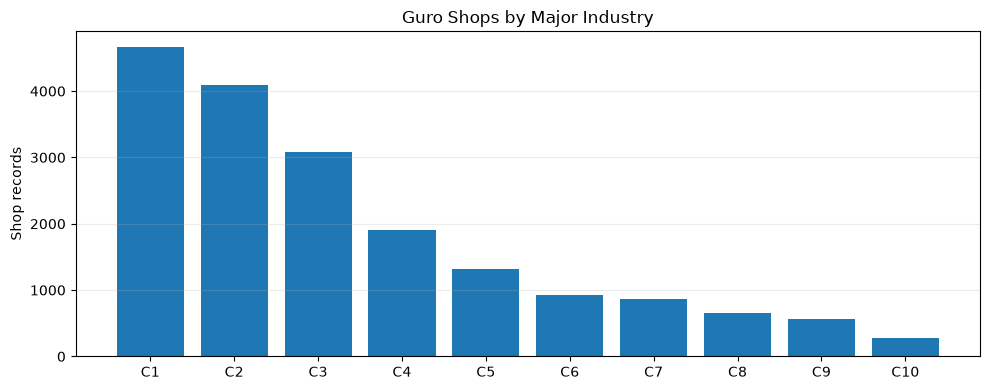

C1: 음식
C2: 소매
C3: 과학·기술
C4: 수리·개인
C5: 교육
C6: 시설관리·임대
C7: 예술·스포츠
C8: 부동산
C9: 보건의료
C10: 숙박


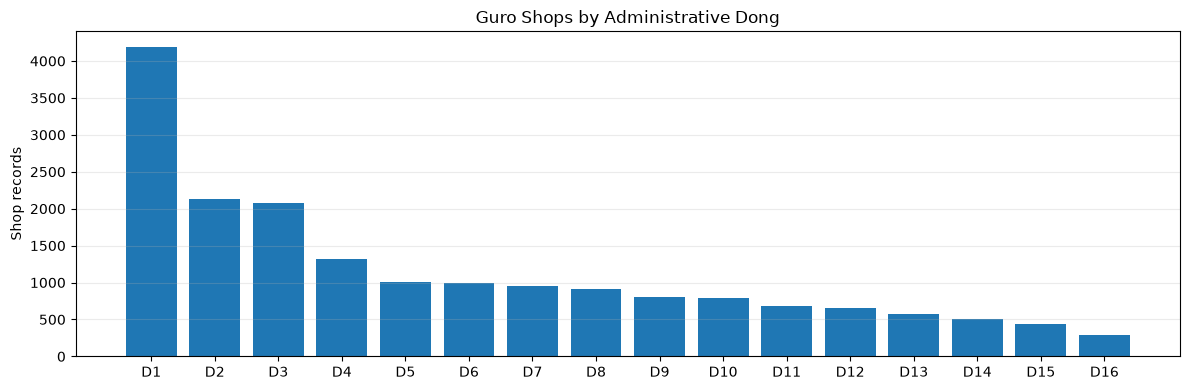

D1: 구로3동
D2: 구로5동
D3: 구로2동
D4: 구로4동
D5: 고척1동
D6: 개봉1동
D7: 신도림동
D8: 고척2동
D9: 오류1동
D10: 오류2동
D11: 가리봉동
D12: 개봉2동
D13: 개봉3동
D14: 수궁동
D15: 항동
D16: 구로1동


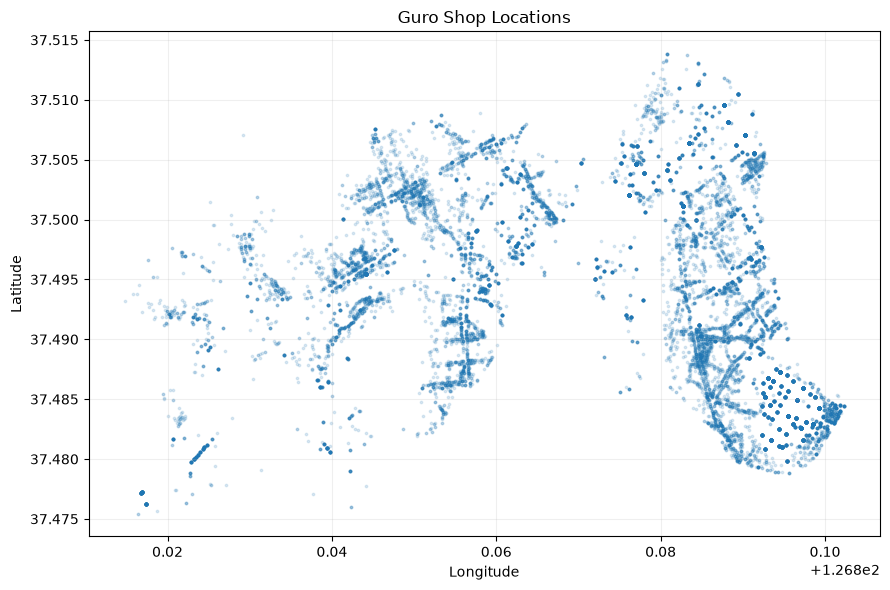

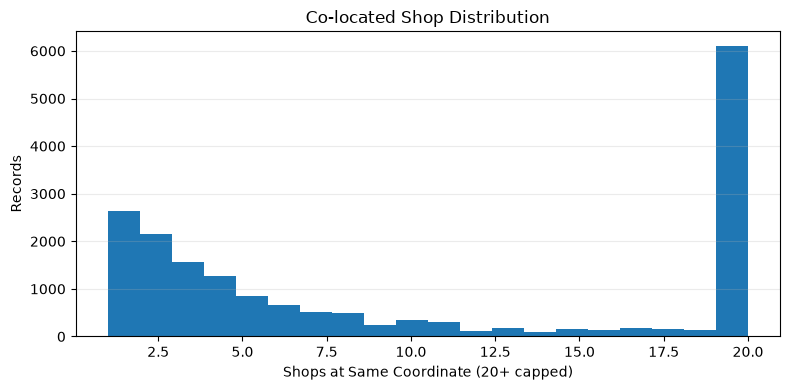

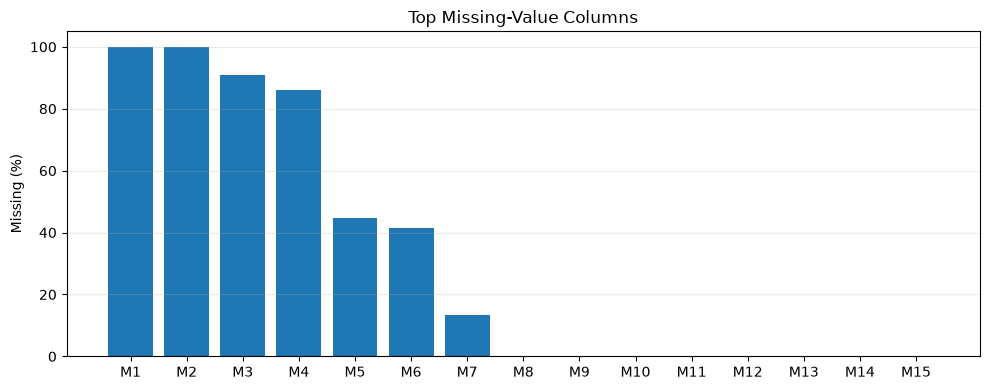

M1: 동정보
M2: 호정보
M3: 지점명
M4: 건물부번지
M5: 건물명
M6: 층정보
M7: 지번부번지
M8: 표준산업분류명
M9: 표준산업분류코드
M10: 상권업종중분류명
M11: 상권업종중분류코드
M12: 상호명
M13: 상가업소번호
M14: 상권업종대분류명
M15: 상권업종대분류코드


In [4]:
# 업종 대분류
major = clean["상권업종대분류명"].value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(major)), major.values)
ax.set_xticks(range(len(major)))
ax.set_xticklabels([f"C{i+1}" for i in range(len(major))])
ax.set_title("Guro Shops by Major Industry")
ax.set_ylabel("Shop records")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

for i, category in enumerate(major.index, 1):
    print(f"C{i}: {category}")
plt.close(fig)

# 행정동 분포
dong = clean["행정동명"].value_counts()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(dong)), dong.values)
ax.set_xticks(range(len(dong)))
ax.set_xticklabels([f"D{i+1}" for i in range(len(dong))])
ax.set_title("Guro Shops by Administrative Dong")
ax.set_ylabel("Shop records")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

for i, name in enumerate(dong.index, 1):
    print(f"D{i}: {name}")
plt.close(fig)

# 좌표 분포
fig, ax = plt.subplots(figsize=(9, 6))
valid = clean["coord_valid_broad"]
ax.scatter(
    clean.loc[valid, "경도"],
    clean.loc[valid, "위도"],
    s=3, alpha=0.15
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Guro Shop Locations")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
plt.close(fig)

# 동일 좌표 공유 상가 수 분포
counts = clean["co_located_shop_count"].dropna()
if not counts.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(
        counts.clip(upper=20).astype(int),
        bins=20
    )
    ax.set_xlabel("Shops at Same Coordinate (20+ capped)")
    ax.set_ylabel("Records")
    ax.set_title("Co-located Shop Distribution")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

# 컬럼별 결측률
missing_top = missing.sort_values(
    "missing_pct", ascending=False
).head(15)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(
    range(len(missing_top)),
    missing_top["missing_pct"]
)
ax.set_xticks(range(len(missing_top)))
ax.set_xticklabels([
    f"M{i+1}" for i in range(len(missing_top))
])
ax.set_ylabel("Missing (%)")
ax.set_title("Top Missing-Value Columns")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
plt.close(fig)

for i, name in enumerate(missing_top.index, 1):
    print(f"M{i}: {name}")

## 5. summary.csv 및 features.csv 생성

In [5]:
records = []

def add(section, metric, category, value, unit=""):
    records.append({
        "section": section,
        "metric": metric,
        "category": category,
        "value": value,
        "unit": unit
    })

overall = {
    "seoul_raw_rows": source_rows,
    "guro_rows": len(clean),
    "original_columns": len(original_columns),
    "unique_shops": clean["상가업소번호"].nunique(),
    "unique_coordinates": len(
        clean.loc[clean["coord_valid_broad"], ["경도", "위도"]]
        .drop_duplicates()
    ),
    "duplicate_shop_id_rows": int(
        clean["duplicate_shop_id_flag"].sum()
    ),
    "duplicate_full_row_rows": int(
        clean["duplicate_full_row_flag"].sum()
    ),
    "duplicate_coordinate_rows": int(
        clean["duplicate_coordinate_flag"].sum()
    ),
    "invalid_coordinate_rows": int(
        (~clean["coord_valid_broad"]).sum()
    ),
    "address_mismatch_rows": int(
        clean["address_district_mismatch_flag"].sum()
    ),
    "review_needed_rows": int(clean["review_needed"].sum())
}

for metric, value in overall.items():
    add("overall", metric, "", value, "records")

for column in original_columns:
    add(
        "missing", "missing_count", column,
        int(clean[column].isna().sum()), "records"
    )
    add(
        "missing", "missing_pct", column,
        float(clean[column].isna().mean()*100), "%"
    )

section_names = {
    "상권업종대분류명": "industry_major",
    "상권업종중분류명": "industry_middle",
    "상권업종소분류명": "industry_minor",
    "행정동명": "administrative_dong",
    "법정동명": "legal_dong"
}

for column, section in section_names.items():
    if column not in clean:
        continue
    for category, count in clean[column].value_counts(
        dropna=False
    ).items():
        label = "(결측)" if pd.isna(category) else str(category)
        add(section, "record_count", label, int(count), "shops")

for column in [
    "경도", "위도",
    "co_located_shop_count", "same_building_shop_count"
]:
    for stat in ["min", "max", "mean", "median", "std"]:
        value = getattr(clean[column], stat)()
        add("numeric", stat, column, value)

# 행정동 × 업종 대분류 교차 집계
cross = (
    clean.groupby(
        ["행정동명", "상권업종대분류명"], dropna=False
    )
    .size()
)
for (dong_name, industry), count in cross.items():
    label = f"{dong_name} / {industry}"
    add("dong_industry", "record_count", label, count, "shops")

summary = pd.DataFrame(records)

# 입력 변수 후보: 실제 보유 자료에서만 생성
feature_columns = [
    "source_row_id",
    "상가업소번호",
    "경도",
    "위도",
    "행정동명",
    "상권업종대분류명",
    "상권업종중분류명",
    "co_located_shop_count",
    "same_building_shop_count",
    "coord_valid_broad",
    "duplicate_coordinate_flag",
    "review_needed"
]

features = clean[feature_columns].rename(columns={
    "상가업소번호": "shop_id",
    "경도": "longitude",
    "위도": "latitude",
    "행정동명": "administrative_dong",
    "상권업종대분류명": "industry_major",
    "상권업종중분류명": "industry_middle"
}).copy()

one_hot = pd.get_dummies(
    clean["상권업종대분류명"].fillna("미분류"),
    prefix="industry_major_type",
    dtype=int
)
features = pd.concat([features, one_hot], axis=1)

print("clean.csv:", clean.shape)
print("summary.csv:", summary.shape)
print("features.csv:", features.shape)
print(features.head().to_string(index=False))

clean.csv: (18338, 48)
summary.csv: (615, 5)
features.csv: (18338, 22)
 source_row_id              shop_id   longitude   latitude administrative_dong industry_major industry_middle  co_located_shop_count  same_building_shop_count  coord_valid_broad  duplicate_coordinate_flag  review_needed  industry_major_type_과학·기술  industry_major_type_교육  industry_major_type_보건의료  industry_major_type_부동산  industry_major_type_소매  industry_major_type_수리·개인  industry_major_type_숙박  industry_major_type_시설관리·임대  industry_major_type_예술·스포츠  industry_major_type_음식
             2 MA010120220808426074  126.897837  37.481475                구로3동             음식              한식                      3                         3               True                       True          False                          0                       0                         0                        0                       0                          0                       0                            0                          

## 6. CSV 저장 및 재읽기 검증

In [6]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

outputs = {
    "clean.csv": clean,
    "summary.csv": summary,
    "features.csv": features
}

loaded = {}

for filename, frame in outputs.items():
    path = OUT_DIR / filename
    frame.to_csv(
        path, index=False, encoding="utf-8-sig"
    )

    # 모든 열을 문자열로 읽어 식별자 선행 0 보존
    reread = pd.read_csv(
        path,
        encoding="utf-8-sig",
        dtype=str,
        keep_default_na=False
    )

    assert reread.shape == frame.shape, filename
    assert list(reread.columns) == list(frame.columns), filename
    assert path.read_bytes().startswith(b"\xef\xbb\xbf")
    loaded[filename] = reread

for filename in ["clean.csv", "features.csv"]:
    assert loaded[filename]["source_row_id"].tolist() == (
        outputs[filename]["source_row_id"].astype(str).tolist()
    )

for col in [
    "상가업소번호", "시군구코드",
    "행정동코드", "법정동코드", "신우편번호"
]:
    if col not in clean:
        continue
    before = clean[col].fillna("").astype(str)
    after = loaded["clean.csv"][col]
    assert before.tolist() == after.tolist(), col

for col in ["경도", "위도"]:
    original = clean[col].to_numpy(dtype=float)
    saved = pd.to_numeric(
        loaded["clean.csv"][col], errors="coerce"
    ).to_numpy(dtype=float)

    assert np.allclose(
        original, saved,
        atol=1e-10, rtol=0, equal_nan=True
    ), col

assert clean["시군구명"].eq("구로구").all()
print("CSV 3개 저장·재읽기 검증 완료")

CSV 3개 저장·재읽기 검증 완료


## 7. README.md 자동 생성 및 검증

In [7]:
descriptions = {
    "source_row_id": "서울 원본 CSV에서의 행 번호",
    "상가업소번호": "상가업소 식별번호",
    "상호명": "상가 상호명",
    "지점명": "지점명",
    "상권업종대분류코드": "상권 업종 대분류 코드",
    "상권업종대분류명": "상권 업종 대분류명",
    "상권업종중분류코드": "상권 업종 중분류 코드",
    "상권업종중분류명": "상권 업종 중분류명",
    "상권업종소분류코드": "상권 업종 소분류 코드",
    "상권업종소분류명": "상권 업종 소분류명",
    "표준산업분류코드": "표준산업분류 코드",
    "표준산업분류명": "표준산업분류명",
    "시도코드": "시도 행정 코드",
    "시도명": "시도명",
    "시군구코드": "시군구 행정 코드",
    "시군구명": "시군구명",
    "행정동코드": "행정동 코드",
    "행정동명": "행정동명",
    "법정동코드": "법정동 코드",
    "법정동명": "법정동명",
    "지번코드": "지번 주소 식별 코드",
    "대지구분코드": "대지 구분 코드",
    "대지구분명": "대지 구분명",
    "지번본번지": "지번 본번",
    "지번부번지": "지번 부번",
    "지번주소": "지번주소",
    "도로명코드": "도로명 코드",
    "도로명": "도로명",
    "건물본번지": "건물 본번",
    "건물부번지": "건물 부번",
    "건물관리번호": "건물 관리 식별번호",
    "건물명": "건물명",
    "도로명주소": "도로명주소",
    "구우편번호": "구 우편번호",
    "신우편번호": "신 우편번호",
    "동정보": "건물 동 정보",
    "층정보": "건물 층 정보",
    "호정보": "건물 호 정보",
    "경도": "경도 좌표",
    "위도": "위도 좌표",
    "coord_valid_broad": "광범위 좌표 범위 검증 여부",
    "duplicate_shop_id_flag": "상가업소번호 중복 여부",
    "duplicate_full_row_flag": "원본 전체 컬럼 중복 여부",
    "duplicate_coordinate_flag": "동일 좌표를 공유하는지 여부",
    "address_district_mismatch_flag": "주소상 구로구 불일치 의심",
    "co_located_shop_count": "정확히 동일한 좌표의 상가 행 수",
    "same_building_shop_count": "같은 건물관리번호의 상가 행 수",
    "review_needed": "품질 검토 대상 여부",
    "section": "통계 구분",
    "metric": "통계 지표",
    "category": "집계 대상·범주",
    "value": "실제 계산한 통계값",
    "unit": "통계값 단위",
    "shop_id": "원본 상가업소번호",
    "longitude": "원본 경도",
    "latitude": "원본 위도",
    "administrative_dong": "원본 행정동명",
    "industry_major": "원본 상권 업종 대분류명",
    "industry_middle": "원본 상권 업종 중분류명"
}

def description(col):
    if col.startswith("industry_major_type_"):
        value = col[len("industry_major_type_"):]
        return f"업종 대분류가 '{value}'이면 1, 아니면 0"
    return descriptions.get(
        col, "원본 제공 컬럼(별도 정의 확인 필요)"
    )

def esc(value):
    return str(value).replace("|", "\\|").replace("\n", " ")

lines = [
    "# 구로구 상가(상권)정보 CSV 사용 설명서",
    "",
    f"- 원본 파일: `{RAW_PATH.name}`",
    f"- 데이터셋: `{DATASET_KEY}`",
    "- 자료 기준: 2026년 9월 (파일명 기준)",
    "- 분석 지역: 서울특별시 구로구",
    "- 추출 조건: `시도명=서울특별시`, `시군구명=구로구`",
    f"- 서울 원본: {source_rows:,}행 × {len(original_columns)}열",
    f"- 구로구 정제: {len(clean):,}행 × {len(clean.columns)}열",
    "",
    "## 전처리",
    "",
    "- 원본 데이터를 분할 읽기한 후 구로구만 추출",
    "- 원본 업종·주소·식별자 값 보존",
    "- 문자열 공백 정리 및 경도·위도 수치형 변환",
    "- 중복 식별자·중복 행·좌표 검토 플래그 생성",
    "- 동일 좌표 및 동일 건물의 상가 수 계산",
    "- 중복 의심 상가 자동 삭제 없음",
    "",
    "## CSV별 컬럼 설명",
    ""
]

purposes = {
    "clean.csv": "구로구 상가 정제 및 품질 검토",
    "summary.csv": "EDA 통계와 집계 결과",
    "features.csv": "공간 분석 및 머신러닝 변수 후보"
}

for filename, frame in outputs.items():
    lines.extend([
        f"### {filename}",
        "",
        f"**목적:** {purposes[filename]}",
        "",
        f"**크기:** {len(frame):,}행 × {len(frame.columns)}열",
        "",
        "| 컬럼명 | 자료형 | 의미 |",
        "|---|---|---|"
    ])

    for col in frame.columns:
        lines.append(
            f"| `{esc(col)}` | `{frame[col].dtype}` "
            f"| {esc(description(col))} |"
        )
    lines.append("")

lines.extend([
    "## summary.csv 집계 기준",
    "",
    "- `overall`: 원본 규모 및 구로구 품질 통계",
    "- `missing`: 원본 컬럼별 결측 건수·비율",
    "- `industry_major`: 업종 대분류별 상가 수",
    "- `industry_middle`: 업종 중분류별 상가 수",
    "- `industry_minor`: 업종 소분류별 상가 수",
    "- `administrative_dong`: 행정동별 상가 수",
    "- `legal_dong`: 법정동별 상가 수",
    "- `numeric`: 좌표 및 동일 위치·건물 상가 수 통계",
    "- `dong_industry`: 행정동 × 업종 대분류 교차 집계",
    "",
    "## features.csv 생성 방식",
    "",
    "- `co_located_shop_count`: 동일 경도·위도 행 수",
    "- `same_building_shop_count`: 동일 건물관리번호 행 수",
    "- `industry_major_type_*`: 업종 대분류 원-핫 인코딩",
    "- `shop_id`는 식별자이며 연속형 예측 변수가 아님",
    "- 위치와 업종은 모델 입력 후보이지 정답 라벨이 아님",
    "",
    "## CSV 간 관계",
    "",
    "- `clean.csv`와 `features.csv`는 상가 등록 행과 1:1 대응",
    "- 연결 식별자: `source_row_id`",
    "- `summary.csv`는 집계 결과로 행 단위가 다름",
    "",
    "## 사용 시 주의사항",
    "",
    "- 상가 위치·업종은 실제 흡연 발생의 정답 데이터가 아님",
    "- 동일 좌표·건물에 여러 상가가 있는 것은 정상일 수 있음",
    "- 좌표 범위 검증은 구로구 행정경계 검증이 아님",
    "- 실제 거리 계산에는 좌표계 검증과 투영변환이 필요",
    "- 250m 격자·도보 네트워크는 아직 결합하지 않음",
    "- 영업시간 및 실제 유동인구는 이 파일만으로 확인 불가",
    "- 분류체계 변경 시 과거 데이터와 직접 비교 주의",
    ""
])

readme_path = OUT_DIR / "README.md"
readme_path.write_text(
    "\n".join(lines), encoding="utf-8"
)

verified = readme_path.read_text(encoding="utf-8")

for frame in outputs.values():
    for col in frame.columns:
        assert f"`{col}`" in verified

print("README.md 저장 및 검증 완료")
for path in sorted(OUT_DIR.iterdir()):
    print(path.name, path.stat().st_size, "bytes")

README.md 저장 및 검증 완료
clean.csv 9687085 bytes
features.csv 2591550 bytes
README.md 7883 bytes
summary.csv 36474 bytes
